# 01 · Configs and loading

The first of six tutorials that walk through the pipeline step by step, with the
same functions `main.py` runs. This one covers what goes in:

1. **The subject config**: which data, where it is, how the sensors are placed
2. **The experiment config**: what to run on it, one section per pipeline step
3. **Loading**: the recordings as the pipeline reads them
4. **One run**: EEG, fNIRS, sensor positions and trials
5. **Ground truth**: the simulated sources and how they are mixed into the channels
   (synthetic data only)
6. **The recordings pruning judges channel quality on**

The tutorials run on one synthetic subject by default. To run them on your own data,
point `SUBJECT_CONFIG` in the next cell at a subject config for it. If its files are in
a format the pipeline does not read yet, add a loader for that format first (notebook
06 shows how). Sections that need ground truth are skipped for data without it.

| Notebook | Topic |
|---|---|
| **01** | Configs and loading |
| 02 | Pruning bad channels |
| 03 | Preprocessing |
| 04 | Unmixing |
| 05 | Results and classification |
| 06 | Your own data, methods and metrics |

In [1]:
# The data and the experiment, relative to the project root.
SUBJECT_CONFIG = "configs/subjects/synthetic/sub01/sub01_snr_fnirs-5_eeg5.yaml"
EXPERIMENT_CONFIG = "configs/experiments/tutorial.yaml"

# For your own data, point SUBJECT_CONFIG at its subject config. If its files are in a
# format the pipeline does not read yet, add a loader for it first (notebook 06).

In [2]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import cedalion.sigproc.quality as quality
from cedalion import units
from cedalion.vis.anatomy.scalp_plot import scalp_plot

from src.config import load_experiment, load_subject
from src.loading import (check_data_format, load_backgrounds, load_recordings, loading_report,
                         select_pruning_recordings)
from src.log import setup_logging
from src.preprocessing.ground_truth import ground_truth_sources
from src.visualization.style import GROUND_TRUTH, shade_stimuli, stimulus_legend

logger = setup_logging()    # quiets the libraries' per-file messages, as main.py does
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)


def relative(text):
    """The text with every path inside the project written relative to it."""
    return str(text).replace(f"{PROJECT_ROOT}/", "")

## 1. The subject config

A subject config says **which data** a run uses. It is a small YAML file per dataset:

- `subject_id` and `format`: the format picks the reader in `src/loading` that knows
  the dataset's file layout (`synthetic` or `buccino`; see notebook 06 to add one)
- `paths`: where the files are, relative to the project root
- `montage`: where the electrodes and optodes sit on the head
- `groups`: the recording sessions. Cross-validation holds out whole groups, so a
  model is never tested on a session it was fit on.
- `test_group`: the group held out for the final test
- `trial_classes`: which trial types make up each side (left, right)

In [3]:
print((PROJECT_ROOT / SUBJECT_CONFIG).read_text())

# Example synthetic subject: one simulated dataset (fNIRS SNR -5 dB, EEG SNR 5 dB) of
# subject sub01. Copy this file for every subject and SNR you simulate; the file name
# is the dataset name, and scripts/run_snr_sweep.py finds every *_snr_*.yaml here.
subject_id: sub01
format: synthetic
paths:
  data: data/synthetic/sub01_snr_fnirs-5_eeg5   # simulation_config.yaml is read from here
  background: data/background_recordings/sub01   # <subject_id>_<group>-raw.fif / .snirf per group
montage:
  eeg:
    standard: standard_1020
  fnirs:
    recording: true                  # optode positions from each run's SNIRF
groups: [sitting_post_rest_1, sitting_post_rest_2, sitting_pre_rest_1, sitting_pre_rest_2, sitting_pre_rest_3]
test_group: sitting_post_rest_1



In [4]:
subject = load_subject(PROJECT_ROOT / SUBJECT_CONFIG)

print(f"Subject {subject.subject_id}, dataset {subject.name}, format {subject.format!r}")
print(f"Groups:        {list(subject.groups)}")
print(f"Test group:    {subject.test_group}")
print(f"Trial classes: {dict(subject.trial_classes)}")

Subject sub01, dataset sub01_snr_fnirs-5_eeg5, format 'synthetic'
Groups:        ['sitting_post_rest_1', 'sitting_post_rest_2', 'sitting_pre_rest_1', 'sitting_pre_rest_2', 'sitting_pre_rest_3']
Test group:    sitting_post_rest_1
Trial classes: {'right': ('right',), 'left': ('left',)}


## 2. The experiment config

An experiment config says **what to run**. It has one section per pipeline step, and
each step reads only its own section. Pruning and preprocessing point to their own
files, since they rarely change between experiments. Every key is explained in
[docs/config_reference.md](../docs/config_reference.md).

In [5]:
print((PROJECT_ROOT / EXPERIMENT_CONFIG).read_text())

# The experiment the tutorial notebooks run: plain CCA as the baseline and three
# regularised methods, with classification. The grids are narrowed to a few values
# around what the full grids of grids.yaml select, so a whole run takes a few minutes.
# For real results use the full grids, e.g. default.yaml.
name: tutorial
hand: both
pruning: ../pruning/default.yaml
preprocessing: ../preprocessing/full_recording.yaml

unmixing:
  grids: ../unmixing/grids.yaml
  methods: [CCA, SparseCCA, ElasticNetCCA, ElasticNetTCCA]
  metrics: [joint_avg, canonical_correlation_avg]
  # n_top: the pair of each hand is chosen among the first 10; a source is often not
  # among the strongest two pairs
  assignment: { method: ground_truth, n_top: 10, eeg_weight: 1.0, fnirs_weight: 1.0 }
  n_components: null   # fit all pairs
  grid_overrides:
    SparseCCA:      { l1_reg: { eeg: [0.1, 0.25], fnirs: [0.1, 0.2] } }
    ElasticNetCCA:  { l1_reg: { eeg: [0.1, 0.2], fnirs: [0.1, 0.2] }, l2_reg: { eeg: [1.0], fn

In [6]:
cfg = load_experiment(PROJECT_ROOT / EXPERIMENT_CONFIG)

print(f"Experiment {cfg.name!r}")
print(f"  pruning:        EEG on each recording whole, fNIRS on {cfg.pruning.window_sec} s "
      f"of a rest period, EEG notch at {list(cfg.pruning.eeg.line_freqs)} Hz")
print(f"  preprocessing:  EEG feature {cfg.preprocessing.eeg_feature!r} in "
      f"{cfg.preprocessing.eeg.feature_band} Hz, fNIRS at {cfg.preprocessing.fnirs_srate} Hz")
print(f"  unmixing:       methods {list(cfg.unmixing.methods)}, metrics {list(cfg.unmixing.metrics)}, "
      f"assignment {cfg.unmixing.assignment.method!r}")
print(f"  classification: {'classes ' + str(list(cfg.classification.classes)) if cfg.classification else 'off'}")

Experiment 'tutorial'
  pruning:        EEG on each recording whole, fNIRS on 60.0 s of a rest period, EEG notch at [50.0, 100.0] Hz
  preprocessing:  EEG feature 'bandpower' in (8.0, 12.0) Hz, fNIRS at 7.4 Hz
  unmixing:       methods ['CCA', 'SparseCCA', 'ElasticNetCCA', 'ElasticNetTCCA'], metrics ['joint_avg', 'canonical_correlation_avg'], assignment 'ground_truth'
  classification: classes ['left', 'right']


## 3. Loading

`check_data_format` checks, before anything is read, that the reader for the
subject's format finds every file it needs. `load_recordings` then reads every run
of every group and applies the montage, and `loading_report` is the summary the
pipeline logs.

In [7]:
check_data_format(subject)
recordings = load_recordings(subject)
print(relative(loading_report(subject, recordings)))

Loaded 15 runs
  sitting_post_rest_1: run_001_seed_2792333187, run_002_seed_1570621782, run_003_seed_492650652
  sitting_post_rest_2: run_001_seed_2799647766, run_002_seed_1777453137, run_003_seed_730335040
  sitting_pre_rest_1: run_001_seed_2418716002, run_002_seed_1946698139, run_003_seed_2902985657
  sitting_pre_rest_2: run_001_seed_4057827324, run_002_seed_3300820366, run_003_seed_734525239
  sitting_pre_rest_3: run_001_seed_4154957764, run_002_seed_1717172445, run_003_seed_2053051004
  data: data/synthetic/sub01_snr_fnirs-5_eeg5
  background: data/background_recordings/sub01


Every run is a `RawRecording` (`src/types.py`), the same type whatever the dataset,
so nothing after loading knows where the data came from:

| Field | What it holds |
|---|---|
| `group`, `run` | which session and run |
| `eeg` | the EEG as an MNE `Raw`, all channels, electrodes placed |
| `fnirs` | the fNIRS amplitude, dims (channel, wavelength, time) |
| `geo3d` | the optode positions |
| `stim` | the trials: onset, duration, trial type |
| `ground_truth` | the simulated sources and mixing, `None` for real data |

In [8]:
rec = recordings[0]
amp, eeg = rec.fnirs, rec.eeg
fnirs_rate = 1 / float(np.median(np.diff(amp.time.values)))

print(f"Run {rec.group}/{rec.run}")
n_eeg = len(eeg.copy().pick("eeg").ch_names)
print(f"EEG:   {len(eeg.ch_names)} channels ({n_eeg} EEG, the rest e.g. EOG) at "
      f"{eeg.info['sfreq']:g} Hz, {eeg.times[-1]:.1f} s")
print(f"fNIRS: {amp.sizes['channel']} channels x {amp.sizes['wavelength']} wavelengths "
      f"{[float(w) for w in amp.wavelength.values]} nm at {fnirs_rate:.2f} Hz")
print(f"Trials: {len(rec.stim)}; ground truth: {'yes' if rec.ground_truth else 'no'}")

Run sitting_post_rest_1/run_001_seed_2792333187
EEG:   41 channels (31 EEG, the rest e.g. EOG) at 250.003 Hz, 175.0 s
fNIRS: 116 channels x 2 wavelengths [760.0, 850.0] nm at 7.40 Hz
Trials: 10; ground truth: yes


## 4. One run

### Sensor positions

The electrodes (left) and the fNIRS channels (right), coloured by the distance
between their source and detector. Short channels (below about 15 mm) mostly see the
scalp; pruning drops channels outside the range set in the pruning config.

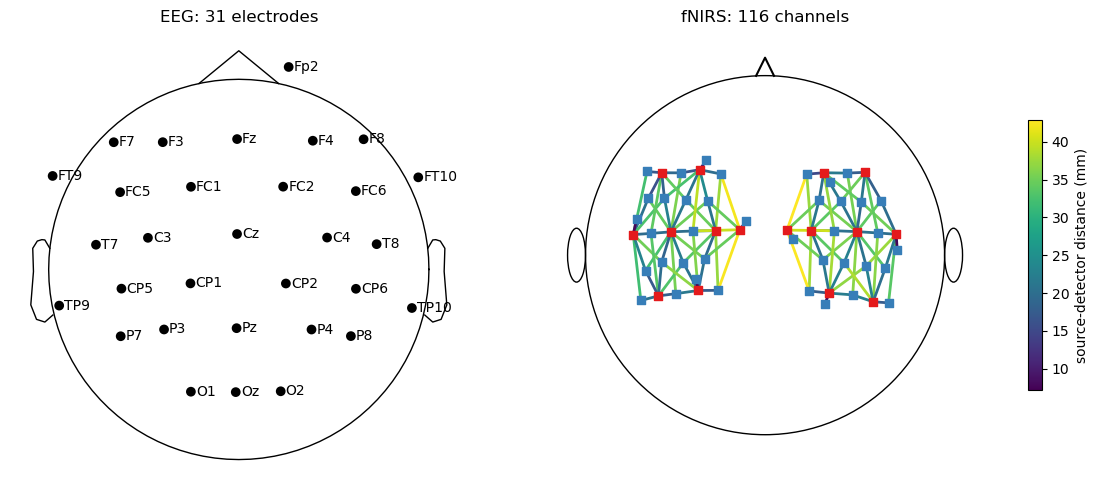

In [9]:
ch_dist, _ = quality.sd_dist(amp, rec.geo3d, [0, 1000] * units.mm)
dist = ch_dist.pint.dequantify().values

fig, (ax_eeg, ax_fnirs) = plt.subplots(1, 2, figsize=(12, 5))
eeg.copy().pick("eeg").plot_sensors(kind="topomap", show_names=True, axes=ax_eeg, show=False)
ax_eeg.set_title(f"EEG: {len(eeg.copy().pick('eeg').ch_names)} electrodes")
scalp_plot(amp, rec.geo3d, dist, ax=ax_fnirs, cmap="viridis",
           title=f"fNIRS: {amp.sizes['channel']} channels", cb_label="source-detector distance (mm)")
plt.tight_layout()
plt.show()

### Trials

The stim table lists every trial. `trial_classes` in the subject config groups the
trial types into the two sides; the pipeline finds one EEG and fNIRS pair per side.

In [10]:
display(rec.stim.head())
print(rec.stim["trial_type"].value_counts().to_string())

,onset,duration,value,trial_type
0,28.49,4.0,0.64,right
1,39.18,4.0,0.60,left
2,51.20,4.0,0.98,left
3,63.14,4.0,0.53,left
4,73.70,4.0,0.52,right


trial_type
left     6
right    4


### The signals around the trials

One EEG channel over each motor cortex (C3 for the right hand, C4 for the left) and
one fNIRS channel, with the trials shaded. The response to a trial is too small to
see in the raw signals: it is the job of preprocessing and unmixing to find it.

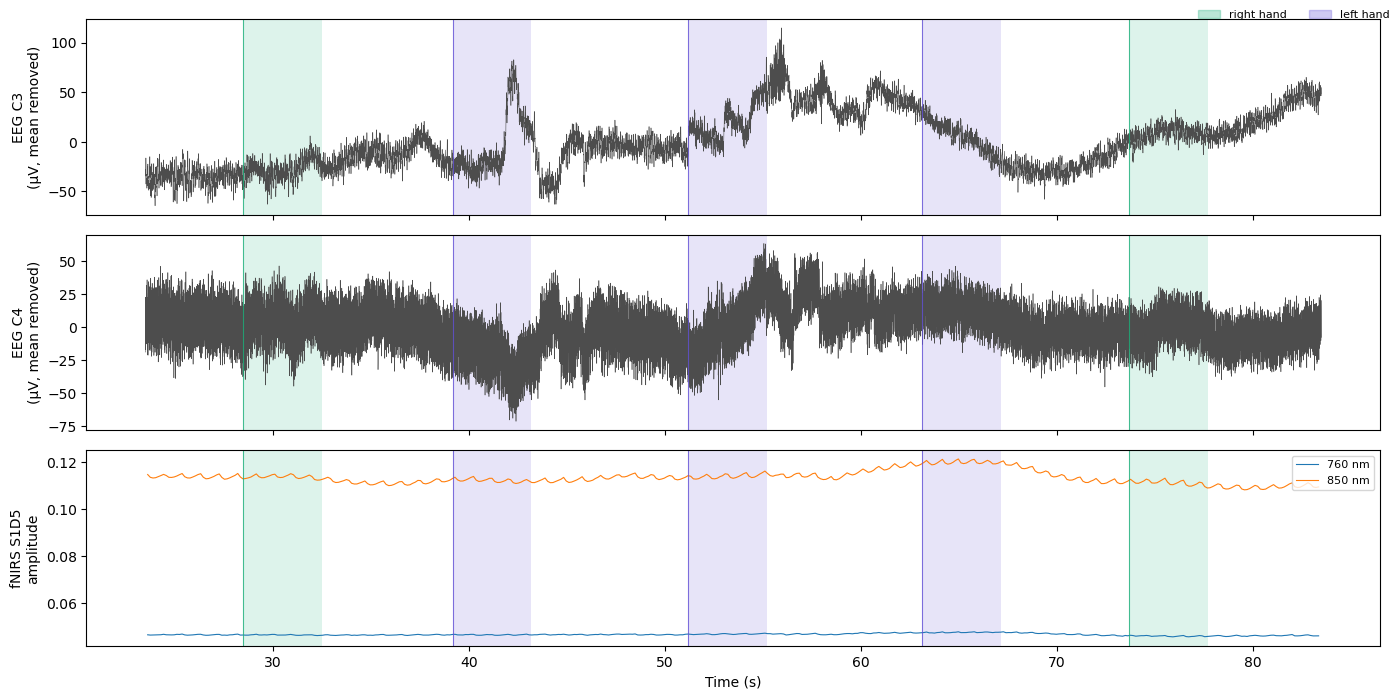

In [11]:
t0 = float(rec.stim["onset"].iloc[0]) - 5
span = (t0, t0 + 60)
eeg_part = eeg.copy().crop(*span).pick([c for c in ("C3", "C4") if c in eeg.ch_names])
fnirs_part = amp.sel(time=slice(*span)).isel(channel=0)

fig, axes = plt.subplots(len(eeg_part.ch_names) + 1, 1, figsize=(14, 7), sharex=True)
for ax, ch in zip(axes, eeg_part.ch_names):
    trace = eeg_part.get_data(picks=ch)[0] * 1e6
    ax.plot(eeg_part.times + span[0], trace - trace.mean(), lw=0.4, color="0.3")
    ax.set_ylabel(f"EEG {ch}\n(µV, mean removed)")
for wl in fnirs_part.wavelength.values:
    axes[-1].plot(fnirs_part.time, fnirs_part.sel(wavelength=wl).pint.dequantify(), lw=0.8,
                  label=f"{wl:g} nm")
axes[-1].set_ylabel(f"fNIRS {str(fnirs_part.channel.values)}\namplitude")
axes[-1].legend(loc="upper right", fontsize=8)
for ax in axes:
    shade_stimuli(ax, rec.stim[rec.stim["onset"].between(*span)])
axes[-1].set_xlabel("Time (s)")
stimulus_legend(fig, rec.stim)
plt.tight_layout()
plt.show()

## 5. Ground truth (synthetic data only)

Synthetic data is generated from known sources: one per hand, in the motor cortex of
the opposite side. Each source has an EEG part (an alpha oscillation that weakens
during the trial) and an fNIRS part (a haemodynamic response that peaks a few seconds
after it). The mixing matrices `A_eeg` and `A_fnirs` say how strongly each source
reaches each channel. Unmixing has to recover the sources from the channels alone;
the ground truth is used only to score how well it did.

In [12]:
gt = rec.ground_truth
if gt is None:
    print("This dataset has no ground truth: sections 5.1 and 5.2 are skipped.")
else:
    sources = [str(s) for s in gt.s_eeg.source.values]
    print(f"Sources: {sources}")
    print(f"A_eeg {dict(gt.A_eeg.sizes)}, A_fnirs {dict(gt.A_fnirs.sizes)}")

Sources: ['right_hand', 'left_hand']
A_eeg {'channel': 31, 'source': 2}, A_fnirs {'channel': 116, 'source': 2, 'wavelength': 2, 'chromo': 2}


### 5.1 Where each source is

Top: how strongly each source reaches each electrode. Bottom: each fNIRS channel's
weight for the source's HbO.

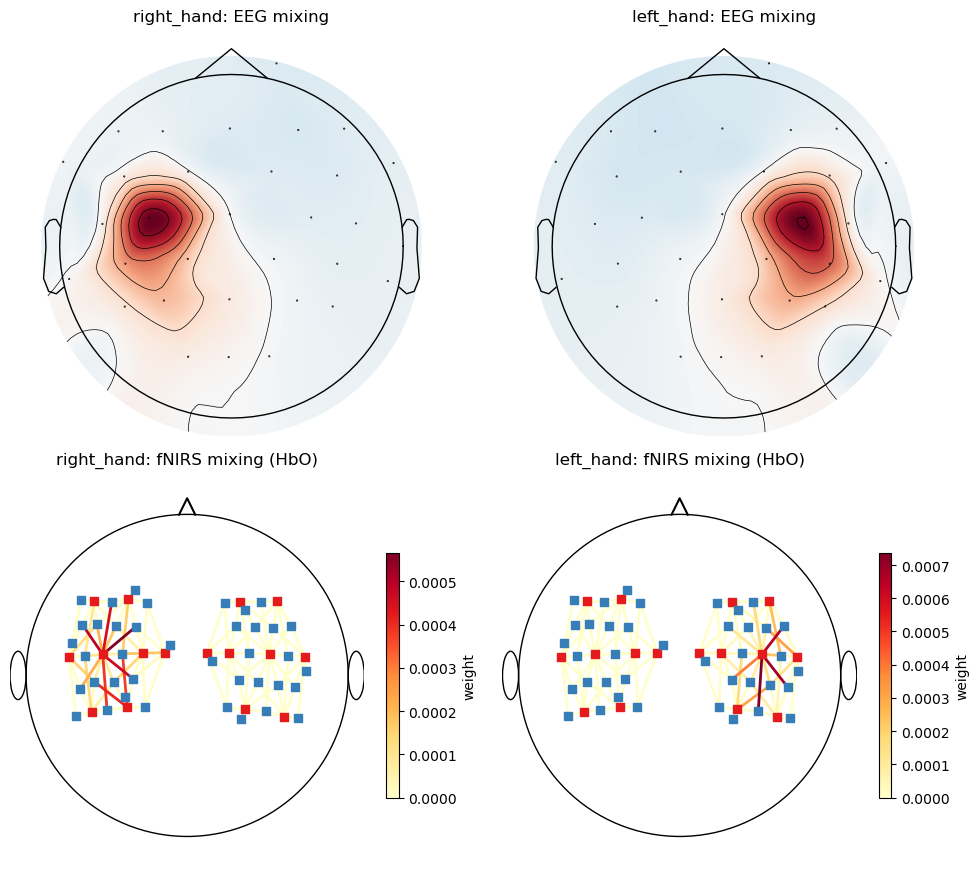

In [13]:
if gt is not None:
    eeg_chs = [c for c in map(str, gt.A_eeg.channel.values) if c in eeg.ch_names]
    info = eeg.copy().pick(eeg_chs).info
    A_hbo = gt.A_fnirs.sel(chromo="HbO").isel(wavelength=0)

    fig, axes = plt.subplots(2, len(sources), figsize=(5 * len(sources), 9))
    for col, src in enumerate(sources):
        weights = gt.A_eeg.sel(source=src, channel=eeg_chs).values
        mne.viz.plot_topomap(weights, info, axes=axes[0, col], show=False, cmap="RdBu_r")
        axes[0, col].set_title(f"{src}: EEG mixing")
        hbo_w = A_hbo.sel(source=src).drop_vars([c for c in A_hbo.coords if c != "channel"])
        scalp_plot(amp, rec.geo3d, hbo_w, ax=axes[1, col], cmap="YlOrRd", zorder="ascending",
                   title=f"{src}: fNIRS mixing (HbO)", cb_label="weight")
    plt.tight_layout()
    plt.show()

### 5.2 What each source does over time

The sources as the pipeline compares them with the recovered components: the EEG
source as alpha band power, the fNIRS source as band-passed HbO, both on the fNIRS
time axis (`ground_truth_sources` applies the preprocessing to them). The band power
drops during a trial of its hand; the HbO rises a few seconds later.

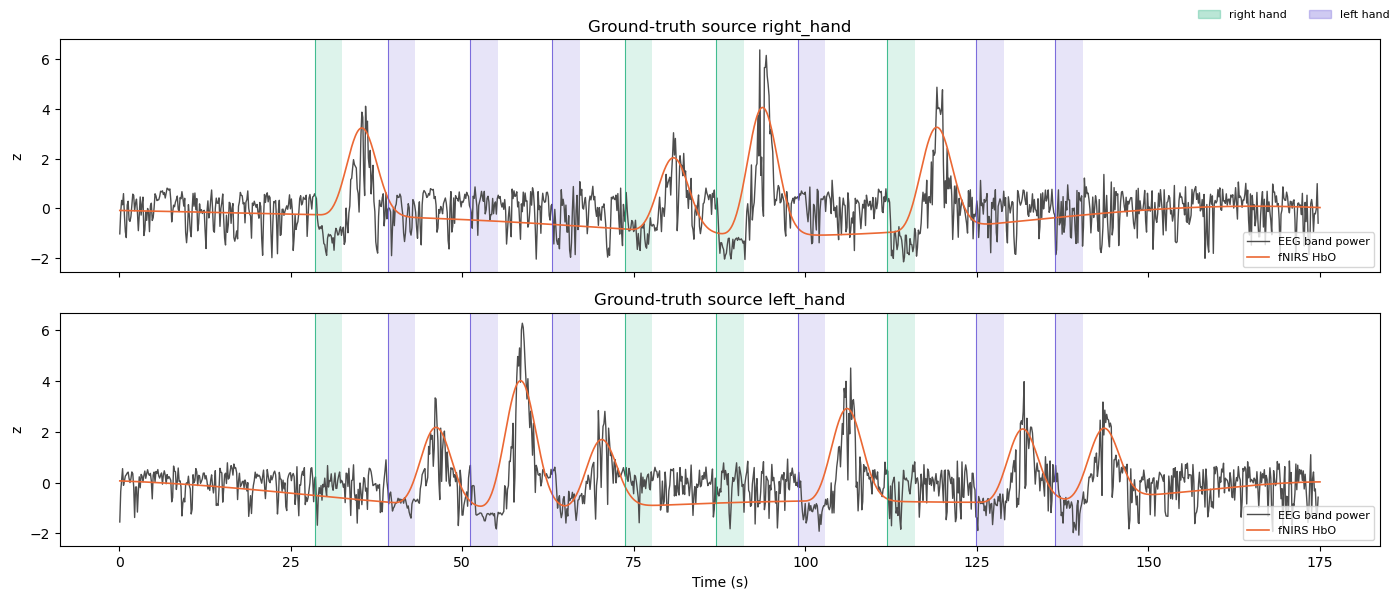

In [14]:
if gt is not None:
    env, hbo = ground_truth_sources(gt, amp.time, cfg.preprocessing)

    fig, axes = plt.subplots(len(sources), 1, figsize=(14, 3 * len(sources)), sharex=True)
    for ax, src in zip(np.atleast_1d(axes), sources):
        e, h = env.sel(source=src), hbo.sel(source=src)
        ax.plot(e.time, (e - e.mean()) / e.std(), color="0.3", lw=1, label="EEG band power")
        ax.plot(h.time, (h - h.mean()) / h.std(), color=GROUND_TRUTH, lw=1.2, label="fNIRS HbO")
        shade_stimuli(ax, rec.stim)
        ax.set_title(f"Ground-truth source {src}")
        ax.set_ylabel("z")
        ax.legend(loc="lower right", fontsize=8)
    np.atleast_1d(axes)[-1].set_xlabel("Time (s)")
    stimulus_legend(fig, rec.stim)
    plt.tight_layout()
    plt.show()

## 6. The recordings pruning judges

Pruning (notebook 02) judges each channel on data without trials, so that a channel's
response to the task cannot make it look bad. For synthetic data that is the
background recording each group was simulated on, without simulated sources:
`load_backgrounds` reads one per group. The EEG of each group is judged on its own
background. The fNIRS is judged on the rest period of the recordings the reader
selects with `select_pruning_recordings`: for synthetic data the first minute of the
earliest background (3 s left out at each end); for Buccino, which has no rest period
long enough, the whole session. Its stim table marks that rest period.

In [15]:
backgrounds = load_backgrounds(subject)
references = select_pruning_recordings(subject, recordings, backgrounds)
print(f"Background recordings: {list(backgrounds)}")
rest = references[0]
print(f"fNIRS judged on {[r.run for r in references]}: EEG {rest.eeg.times[-1]:.1f} s, "
      f"fNIRS {rest.fnirs.sizes['channel']} channels")
display(rest.stim)

Background recordings: ['sitting_post_rest_1', 'sitting_post_rest_2', 'sitting_pre_rest_1', 'sitting_pre_rest_2', 'sitting_pre_rest_3']
fNIRS judged on ['sub01_sitting_pre_rest_1']: EEG 175.0 s, fNIRS 116 channels


,onset,duration,value,trial_type
0,3.0,54.0,1.0,rest


## Next

Notebook 02 finds the bad channels on these recordings and removes them from every
run.